<p align="center">
  <img src="https://www.copernicuslac-chile.eu/wp-content/uploads/2024/05/logo_copernicuslac_chile.svg" alt="Copernicus LAC Chile" width="1200"/>
</p>

# Taller Océanos: México, ODS 14
## SST y clorofila de CopernicusLAC frente a los indicadores del ODS 14 y los datos del SIODS (INEGI)

Este notebook es la guía práctica del bloque **Monitoreo de Costas** (11 de noviembre de 2026, 13:00–15:30). Trabaja con los productos mensuales de **temperatura superficial del mar (SST)** y **clorofila-a (CHL)** de CopernicusLAC para 2024 y con los valores oficiales que publica México en el **SIODS** y la ONU.

Cada grupo elige una de las cinco áreas del mar mexicano: Baja California – Pacífico, Golfo de California, Pacífico sur, Golfo de México o Caribe mexicano. Los datos de 2024 son los únicos configurados en este notebook.

## Índice del taller

0. [Contexto y configuración](#parte-0)
1. [Exploración de los productos](#parte-1)
2. [Selección del área de trabajo](#parte-2)
3. [ODS 14.1.1: clorofila y eutrofización](#parte-3)
4. [ODS 14.5.1: cobertura de zonas protegidas](#parte-4)
5. [ODS 14.2.1, ficha del grupo y exportación](#parte-5)
   - [Preguntas de discusión final](#discusion)
   - [Anexo opcional](#anexo)

La lógica pedagógica es la siguiente:

```text
reconocer los datos → elegir área → leer SST y CHL → comparar con el dato oficial 14.1.1 → reproducir el 14.5.1 del SIODS → contexto 14.2.1 → ficha
```

| Indicador | ¿Lo publica México en el SIODS (INEGI)? | Valor oficial de referencia | Papel de los productos CopernicusLAC |
|---|---|---|---|
| **14.1.1** Eutrofización costera | No | ONU, nivel 1: `EN_MAR_CHLDEV` = 2,35 % (2022) | **Componente** (`EN_MAR_CHLCONC`) y patrones espaciales |
| **14.5.1** Zonas protegidas | **Sí**: 23,78 % (2024) | ONU, método KBA: 64,33 % (2024) | **Contexto** ambiental de las ANP; el cálculo es vectorial |
| **14.2.1** Enfoques ecosistémicos | No | ONU: 1 (sí), cuatro POEM | **Contexto** ambiental de los POEM; no entra en el cálculo |

---

<a id="parte-0"></a>

## Parte 0. Contexto y configuración

### Objetivo

Preparar el entorno y cargar todos los insumos: los dos NetCDF de 2024, las capas vectoriales (ANP federales de CONANP, ZEE, áreas de trabajo) y la tabla de valores oficiales del SIODS y de la ONU.

### Cómo recorrer este notebook

Ejecuta las celdas de arriba hacia abajo. En los puntos marcados como **Revisión**, detente para leer la tabla o el mapa antes de avanzar. Las selecciones se hacen con **menús interactivos**; si no los ves, revisa que el kernel sea **Python (2026coplac)**.

### 0.1 Preparación del entorno

Esta celda carga las funciones del taller (`scripts/oceanos_mexico_functions.py`) y los datos. **Tarda uno o dos minutos.**

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
BASE_DIR = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / 'scripts').is_dir() and (p / 'environment.yml').exists())
sys.path.insert(0, str(BASE_DIR / 'scripts'))
from oceanos_mexico_functions import *
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.labelsize': 10})

preparar_entorno()

AVISO: CMC_SST_2024MM_2026-10-13T153231_L4.nc: lat sin units; interpretación geográfica confirmada explícitamente.
AVISO: CMC_SST_2024MM_2026-10-13T153231_L4.nc: lon sin units; interpretación geográfica confirmada explícitamente.
AVISO: CMC_CHL_2024MM_2026-10-13T153338_L4.nc: lat sin units; interpretación geográfica confirmada explícitamente.
AVISO: CMC_CHL_2024MM_2026-10-13T153338_L4.nc: lon sin units; interpretación geográfica confirmada explícitamente.
✅ Datos cargados
   SST: 12 meses, grilla 936×1714
   CHL: 12 meses, grilla 1871×3427
   ANP federales: 232 (con superficie marina: 40)


{'BASE': WindowsPath('C:/Users/marin/COPLAC/Taller_Mexico_ODS14_asistentes'),
 'sst': <xarray.DataArray 'analysed_sst' (time: 12, lat: 936, lon: 1714)> Size: 77MB
 array([[[26.609985, 26.639984, 26.639984, ...,       nan,       nan,
                nan],
         [26.600006, 26.619995, 26.670013, ...,       nan,       nan,
                nan],
         [26.709991, 26.630005, 26.600006, ...,       nan,       nan,
                nan],
         ...,
         [15.149994, 15.320007, 15.440002, ...,       nan,       nan,
                nan],
         [15.209991, 15.25    , 15.160004, ...,       nan,       nan,
                nan],
         [15.200012, 15.320007, 15.25    , ...,       nan,       nan,
                nan]],
 
        [[26.769989, 26.98999 , 26.679993, ...,       nan,       nan,
                nan],
         [26.670013, 26.660004, 26.690002, ...,       nan,       nan,
                nan],
         [26.670013, 26.660004, 26.660004, ...,       nan,       nan,
              

### 0.2 ¿Hay internet en la sala?

El notebook funciona **sin internet**: los datos, los menús, el visor mensual y la calculadora son locales. Solo dos elementos dependen de la red:

- el **mapa interactivo** de la Parte 2 (Folium y el fondo de OpenStreetMap se cargan desde internet);
- el logo del encabezado.

La celda siguiente comprueba la conexión. Si no hay internet, el mapa interactivo se sustituye por un **mapa estático** con las ANP numeradas y una tabla con sus nombres.

Si la red de la sala es lenta o inestable, fuerza el modo sin internet escribiendo `SIN_INTERNET = True` antes de ejecutar.

In [2]:
# None = detectar automáticamente · True = trabajar sin internet · False = forzar el mapa interactivo
SIN_INTERNET = None

configurar_conexion(SIN_INTERNET)

🌐 Modo CON internet (detectado automáticamente): se usará el mapa interactivo con fondo de OpenStreetMap.


False

<a id="parte-1"></a>

## Parte 1. Exploración de los productos

### Objetivo del bloque

Reconocer qué datos tenemos antes de usarlos: periodo, grilla y huella de los NetCDF, y dónde quedan las cinco áreas de trabajo.

- **SST** (`analysed_sst`): producto L4 mensual, grilla de 0,02°, convertido de K a °C.
- **CHL** (`chlor_a`): producto L4 mensual multisensor, grilla de 0,01° (~1 km), en mg m⁻³.

Un producto **L4** está completo porque rellena los huecos (nubes) con interpolación o modelo: alta cobertura no significa observación en cada píxel.

### Paso 1.1 Inventario y áreas

**Resultado esperado:** una tabla con los dos archivos (12 meses de 2024) y un mapa con las cinco áreas recortadas a la ZEE.

,tipo,archivo,fechas,inicio,fin,lat_min,lat_max,lon_min,lon_max,dlat_grados
0,SST,CMC_SST_2024MM_2026-10-13T153231_L4.nc,12,2024-01-01 00:00:00,2024-12-01 00:00:00,13.820,32.520,-120.139999,-85.879997,0.02
1,CHL,CMC_CHL_2024MM_2026-10-13T153338_L4.nc,12,2024-01-01 00:00:00,2024-12-01 00:00:00,13.825,32.525,-120.145000,-85.885000,0.01


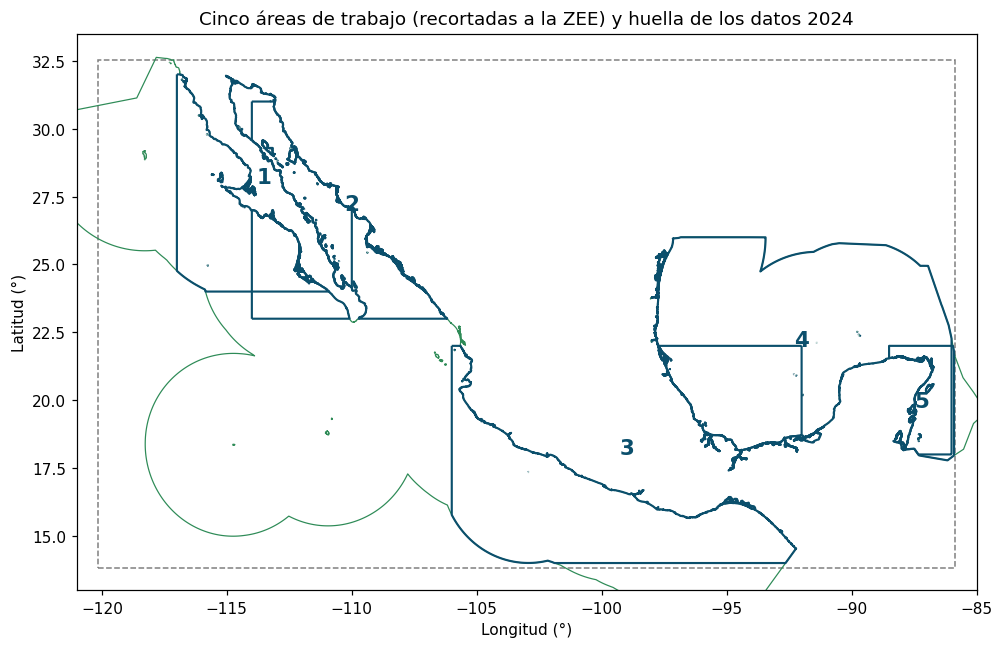

,id_area,nombre,poem_referencia
0,1,Baja California – Pacífico,POEM Pacífico Norte (2018)
1,2,Golfo de California,POEM Golfo de California (2006)
2,3,Pacífico sur,"POEM Pacífico Centro-Sur (en preparación, 2023)"
3,4,Golfo de México,POEM Golfo de México y Mar Caribe (2012)
4,5,Caribe mexicano,POEM Golfo de México y Mar Caribe (2012)


In [3]:
explorar_productos()

**Revisión:** ¿la huella de los datos (rectángulo gris) cubre toda la ZEE mexicana? ¿Qué parte del Caribe queda fuera?


<a id="parte-2"></a>

## Parte 2. Selección del área de trabajo

### Objetivo del bloque

Elegir el área del grupo. El análisis se hace dentro de:

```text
área de trabajo ∩ ZEE de México
```

Cada área se asocia, de forma aproximada, a un Programa de Ordenamiento Ecológico Marino (POEM), que se usará en la Parte 5.

### Paso 2.1 Elegir área y grupo

1. elige el área en el menú;
2. escribe el nombre del grupo (letras, números y guion bajo);
3. pulsa **Confirmar área**.

**Resultado esperado:** un mapa interactivo del área con las ANP que tienen superficie marina; pasa el cursor sobre una ANP para ver su nombre y categoría. **Sin internet** (Paso 0.2) aparece un mapa estático con las ANP coloreadas por categoría, numeradas, y una tabla con sus nombres.

In [5]:
launch_seleccion_area(id_area_inicial=4, grupo_inicial='grupo_01')

<a id="parte-3"></a>

## Parte 3. ODS 14.1.1: clorofila y eutrofización

### Objetivo del bloque

**14.1.1** mide eutrofización costera y basura plástica. Para la clorofila, los metadatos ONU (actualización 28-03-2025) incluyen tres series:

- `EN_MAR_CHLANM` (anomalía) y `EN_MAR_CHLDEV` (desviaciones): **nivel 1 global**, calculadas por UNEP con OC-CCI a 4 km, referencia mensual 2000–2004 y percentil 90 de las diferencias positivas sobre todas las ZEE. Con un solo año (2024) y otro producto **no se pueden reproducir**.
- `EN_MAR_CHLCONC` (concentración, mg L⁻¹): figura en la lista de series de los metadatos ONU y corresponde a datos nacionales (nivel 2) «donde exista capacidad nacional». Aquí se **caracteriza** con CHL CopernicusLAC; no es una estadística validada.

El SIODS de México no publica 14.1.1: hoy el único dato para el país es el global de nivel 1.

### Paso 3.1 Visor mensual de SST y CHL

Cambia la variable y mueve el mes. El visor arranca en el mes sugerido para tu área.

**Revisión:** ¿dónde hay agua fría junto a la costa? ¿Coincide con CHL alta?

In [7]:
launch_visor_mensual()

### Lectura oceanográfica (sin índice): ¿dónde hay surgencia?
- **Área 1:** franjas de agua fría pegadas a la costa del Pacífico de Baja California en primavera, con CHL alta en la misma franja: firma de **surgencia costera** inducida por viento.
- **Área 3:** en invierno, una lengua fría frente al Golfo de Tehuantepec: **mezcla y surgencia por viento** que cruza el istmo (los «tehuanos»), no surgencia de borde oriental.
- **Áreas 4 y 5:** la CHL alta en la plataforma del Golfo puede deberse a ríos, sedimento y materia orgánica disuelta (CDOM), no solo a fitoplancton. En aguas turbias el algoritmo de color del océano sobreestima la CHL.

Una CHL alta **no demuestra eutrofización**: también responde a surgencia, mezcla y estación. Separar el aporte humano requiere nutrientes, oxígeno y cargas de los ríos (eso es el ICEP, `EN_MAR_COEUPO`, que este taller no calcula).

### Paso 3.2 Ciclo anual y concentración de clorofila

**Resultado esperado:** la serie mensual de SST y CHL del área y la concentración media de 2024 (componente `EN_MAR_CHLCONC`).

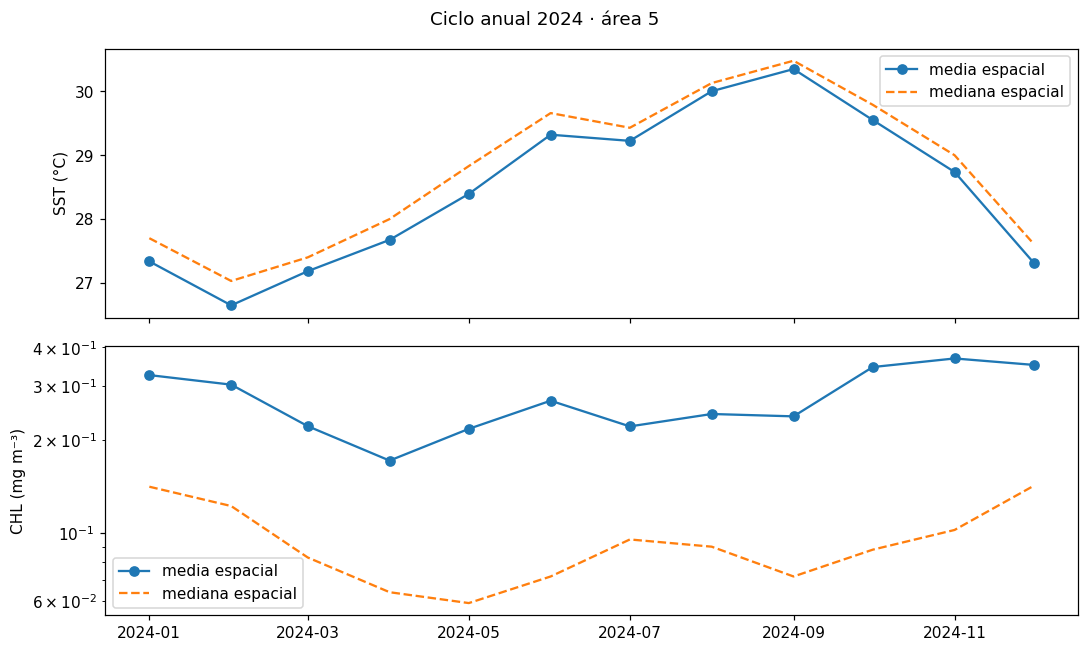

CHL media 2024 (media de 12 meses): 0.273 mg m⁻³ = 0.000273 mg L⁻¹
Cobertura mínima del campo: 99.2 % · producto L4: puede incluir relleno


In [8]:
run_series_14_1_1();

### Paso 3.3 ¿Y si llevamos CopernicusLAC a 4 km?
El método oficial usa OC-CCI a **4 km** (grilla global de 1/24°). La resolución sí se puede homogeneizar: la celda siguiente agrega la CHL de CopernicusLAC (~1 km) a esa misma grilla.

- **Operador:** media en log10 (media geométrica), coherente con la distribución lognormal de la CHL y con el operador temporal que declara el propio producto.
- **Costa:** un píxel de 4 km se conserva solo si al menos la mitad de sus celdas finas es agua válida, como en un producto de 4 km. Los píxeles mixtos de costa desaparecen.

Lo que el remuestreo **no** resuelve: el algoritmo y los sensores siguen siendo los de CopernicusLAC, no los de OC-CCI; no hay referencia 2000–2004; y el umbral es el percentil 90 de las diferencias positivas en todas las ZEE del mundo. Homogeneizar la resolución es una condición necesaria, no suficiente.

**Resultado esperado:** una tabla mensual y dos mapas del mes elegido en el visor: ~1 km y 4 km.

Media anual: 0.273 mg m⁻³ a ~1 km · 0.265 mg m⁻³ a 4 km
Celdas de ~1 km que caen en píxeles de 4 km descartados: 0.84 %
Mediana de CHL en esas celdas: 0.85 mg m⁻³ frente a 0.09 mg m⁻³ en toda el área


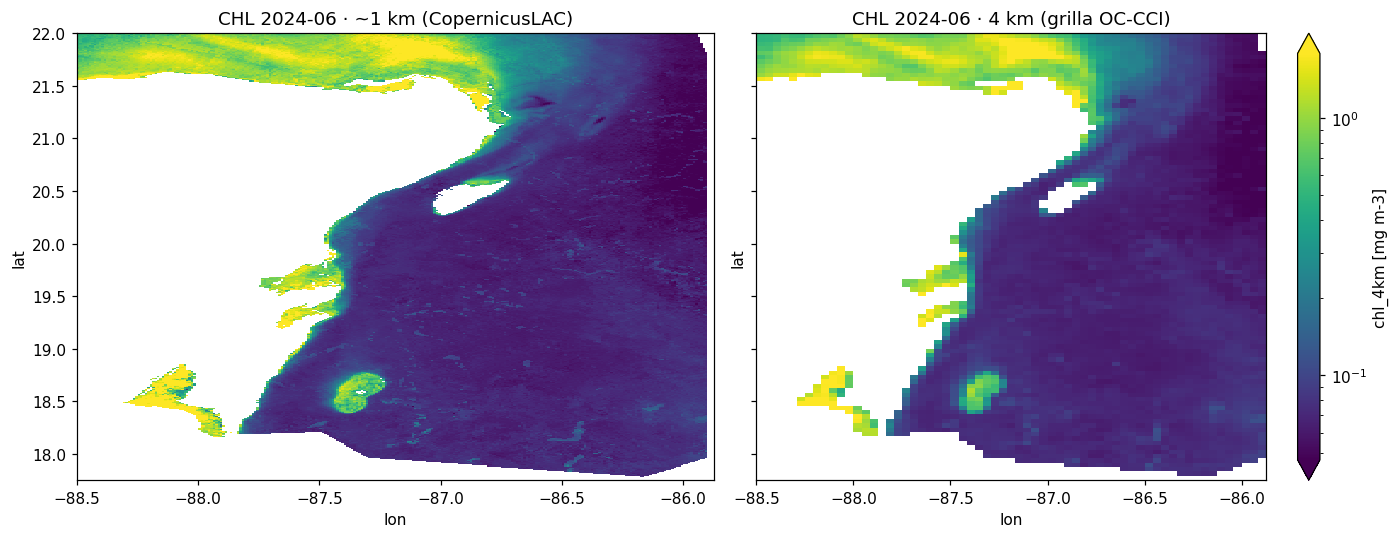

In [9]:
run_4km();

**Lectura.** En el conjunto del área, pasar a 4 km casi no cambia la media: se pierde menos del 1 % de las celdas de ~1 km. Esas celdas son sobre todo las de la costa (y, en meses con huecos, los bordes de los huecos), donde la CHL es varias veces más alta que la mediana del área. Es decir: la resolución no impide comparar con el dato oficial, pero el dato oficial a 4 km **no ve** justamente la franja donde ocurre la eutrofización (lagunas, desembocaduras). Cuidado: en esa franja turbia la CHL satelital también es menos fiable, porque sedimento y materia orgánica disuelta la sobrestiman.

Observe también el mapa de ~1 km: si aparecen bloques rectangulares o rayados que no siguen la oceanografía, son artefactos de procesamiento del producto y conviene reportarlos al servicio.

### Paso 3.4 El dato oficial para México

La ONU publica para México las desviaciones (`EN_MAR_CHLDEV`) y la anomalía (`EN_MAR_CHLANM`) de clorofila, calculadas por UNEP a escala global. Es el único dato de 14.1.1 que existe hoy para el país.

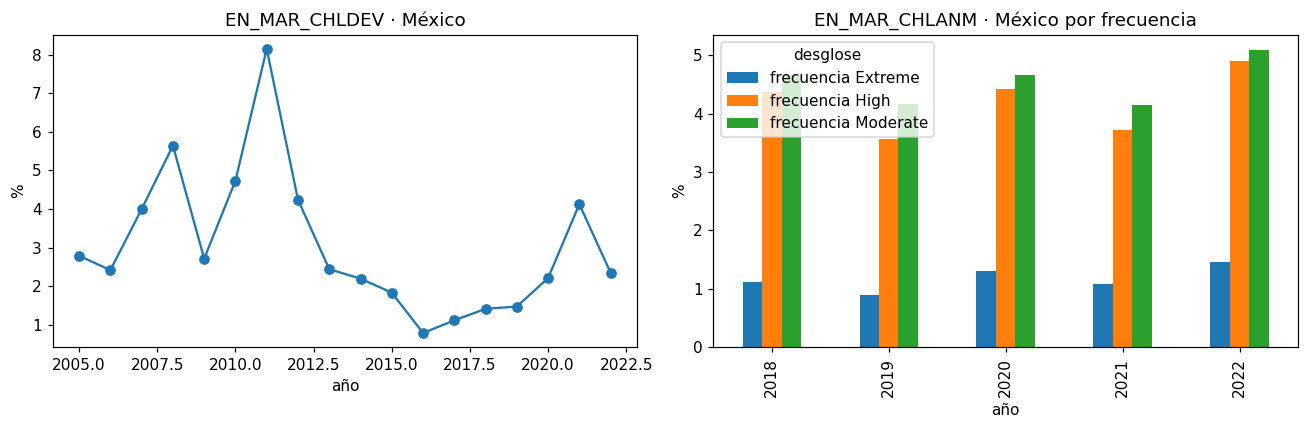

Último valor CHLDEV: 2022 → 2.35 %


In [10]:
show_referencia_onu_14_1_1()

### Revisión
1. ¿El máximo de CHL de su área coincide con el mínimo de SST? ¿Qué proceso sugiere?
2. Al pasar a 4 km, ¿cuánto cambia la media de su área y qué tienen en común las celdas que se pierden?
3. ¿Por qué, aun a 4 km, el valor 2024 de CopernicusLAC no puede ser un punto más de la serie `EN_MAR_CHLDEV`?

### ¿Qué haría falta para que México publique el 14.1.1 con datos nacionales?
Hoy el SIODS no publica el 14.1.1; el único dato para México es el global de nivel 1 de la ONU (`EN_MAR_CHLDEV` = 2,35 % en 2022). Los metadatos ONU prevén que los datos nacionales, in situ o de teledetección, complementen, validen y, si es posible, sustituyan a los globales.

| Pieza | Qué falta | Quién podría aportarlo |
|---|---|---|
| **Serie satelital de CHL** | Serie larga y homogénea (mismo producto y algoritmo) con un periodo de referencia, y validación en aguas costeras turbias | CopernicusLAC (producto regional ~1 km); OC-CCI como referencia global |
| **Validación in situ** | Mediciones de clorofila-a y nutrientes en la costa para contrastar el satélite | Programas de monitoreo costero y académicos |
| **Umbral y método** | Usar el umbral global (comparable con la ONU) o uno nacional documentado; máscara oficial de mar territorial y ZEE | Unidad del Estado responsable, con UNEP como custodio |
| **ICEP (`EN_MAR_COEUPO`)** | Cargas de nitrógeno, fósforo y sílice en las desembocaduras, por cuenca | Monitoreo de calidad del agua y caudales en ríos; cuencas hidrográficas del INEGI |
| **Institucionalidad** | Unidad del Estado responsable, metadato y calendario en el SIODS | INEGI y SEMARNAT |

**Lo que CopernicusLAC puede aportar ya:** el componente de concentración (`EN_MAR_CHLCONC`) a ~1 km, la validación costera del dato global a 4 km y la desagregación espacial que propone UNEP.

<a id="parte-4"></a>

## Parte 4. ODS 14.5.1: cobertura de zonas protegidas

### Objetivo del bloque

El mismo código, **14.5.1**, tiene dos métodos distintos:

| | SIODS (INEGI, cálculo SEMARNAT) | ONU global (`ER_MRN_MPA`) |
|---|---|---|
| Fórmula | superficie marina de ANP federales / superficie de la ZEE × 100 | media de la cobertura PA/OECM de cada **Marine KBA** |
| Fuentes | CONANP (IGANP 2025) y ZEE de CONABIO (2011) | WDKBA, WDPA y WD-OECM |
| México 2024 | **23,78 %** | **64,33 %** |

No se contradicen: responden a preguntas distintas («¿qué parte del mar está protegida?» frente a «¿qué parte de los sitios clave para la biodiversidad está protegida?»). La capa `anp.gpkg` del paquete es la misma fuente CONANP que usa el SIODS, así que el numerador nacional se puede **reproducir**.

### Paso 4.1 Reproducir la serie del SIODS

Se suma la superficie marina declarada de cada ANP (`S_MARINA`) por año de su primer decreto y se compara con el numerador que publica el SIODS. Dividiendo el numerador publicado por el porcentaje publicado se obtiene la ZEE que usa el SIODS.

**Resultado esperado:** la diferencia del numerador (en hectáreas), la ZEE implícita y la serie 1993–2025 junto al valor global de la ONU.

,anio,SIODS_ha,S_MARINA_ha,diferencia_ha,SIODS_pct
23,2016,54665351.0,5.466535e+07,0.312856,17.354521
24,2017,69458613.0,6.945861e+07,0.212856,22.050913
25,2018,69458613.0,6.945861e+07,0.212856,22.050913
26,2019,69458613.0,6.945861e+07,0.212856,22.050913
27,2020,69458613.0,6.945861e+07,0.212856,22.050913
28,2021,69458613.0,6.945861e+07,0.212856,22.050913
29,2022,69458613.0,6.945861e+07,0.212856,22.050913
30,2023,69458613.0,6.945861e+07,0.212856,22.050910
31,2024,74904155.0,7.490416e+07,0.388631,23.779701
32,2025,74904155.0,7.490416e+07,0.388631,23.779701


Diferencia máxima del numerador: 0.4 ha
ZEE implícita en el SIODS: 3,149,920 km² (constante en toda la serie)


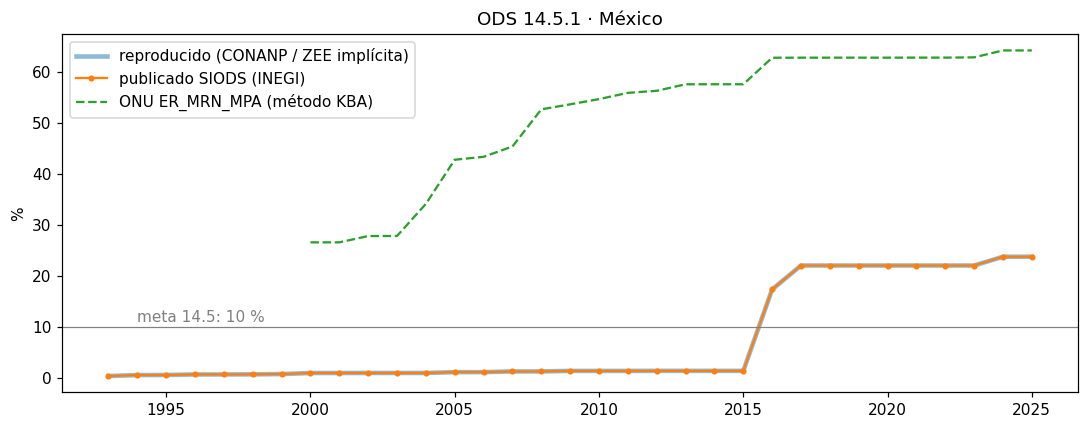

In [12]:
run_reproduccion_siods();

### Paso 4.2 Calculadora del 14.5.1

Elige un **numerador** (superficie protegida) y un **denominador** (superficie de la ZEE) y pulsa **Calcular**. También puedes escribir otro denominador.

**Revisión:** ¿cuánto cambia el resultado al cambiar solo el denominador? ¿Por qué conviene publicar la ZEE usada junto al porcentaje?

In [14]:
launch_calculadora_14_5_1()

### Paso 4.3 Por categoría de manejo y en tu área

UNEP propone desagregar el 14.5.1 por categoría de manejo. La tabla muestra cuánto aporta cada categoría nacional (RB, PN, APFF, SANT…) a la cobertura de la ZEE. Después se calcula la cobertura dentro de tu área y se comparan SST y CHL dentro y fuera de las ANP marinas.

**Resultado esperado:** tabla por categoría, porcentaje de tu área y tabla de contexto ambiental.

In [15]:
run_categorias_y_area();

,CAT_MANEJO,n_anp,S_MARINA_km2_declarada,protegido_km2_geometrico,cobertura_pct_geometrica
4,RB,48,534384.88,534734.49,16.78
3,PN,79,209918.41,209907.63,6.59
0,APFF,57,3282.62,7217.62,0.23
5,SANT,28,1455.65,1496.41,0.05
1,APRN,15,0.00,0.00,0.00
2,MN,5,0.00,0.00,0.00


Área 5: 61,095 km² protegidos de 77,183 km² de ZEE = 79.2 %


mean     min     max
variable clase                                        
CHL      dentro de ANP marinas   0.202   0.134   0.270
         resto del área          0.542   0.314   0.789
SST      dentro de ANP marinas  28.619  26.845  30.398
         resto del área         27.950  25.913  30.167

Una diferencia dentro/fuera describe ubicación (costa, profundidad), no efecto de la protección.


### Revisión
1. El numerador se reproduce casi a la hectárea. ¿De dónde sale entonces la diferencia entre 23,78 % y la cobertura calculada con la ZEE de Marine Regions?
2. ¿Por qué el valor global (64 %) es casi el triple del nacional?
3. El salto de 2016 corresponde a pocas ANP muy grandes y alejadas de la costa. ¿Qué dice eso sobre la cobertura por categoría y sobre la cercanía de la protección a las presiones costeras?

<a id="parte-5"></a>

## Parte 5. ODS 14.2.1, ficha del grupo y exportación

### Objetivo del bloque

`EN_SCP_ECSYBA` es **binario e institucional**: 1 si el país aplica enfoques ecosistémicos a la gestión de sus zonas marinas. Se desagrega por instrumento, etapa del plan, zona marítima y mecanismo de coordinación. México figura con **1** en la base ONU, con cuatro Programas de Ordenamiento Ecológico Marino (POEM).

SST y CHL no entran en el cálculo. Lo que sí pueden hacer es describir el ambiente de la región que ordena cada POEM: estacionalidad, frentes, zonas productivas. Es información de apoyo para el plan, no evidencia del indicador.

### Paso 5.1 Valor oficial y estacionalidad de la región del POEM

In [17]:
run_14_2_1();

,anio,valor,desglose
125,2006,1.0,POEM del Golfo de California (2006); etapa: im...
126,2012,1.0,POEM y Regional del Golfo de México y Mar Cari...
127,2018,1.0,POEM y Regional del Pacífico Norte (2018); eta...
128,2023,1.0,POEM y Regional del Pacífico Centro-Sur; etapa...
129,2023,1.0,total nacional


Área 5 ≈ POEM Golfo de México y Mar Caribe (2012) (aproximación: la ventana no es el polígono oficial del POEM)


,mes_min,min,mes_max,max,amplitud
variable,,,,,
CHL,2024-04,0.171,2024-11,0.368,0.197
SST,2024-02,26.648,2024-09,30.350,3.701


**Revisión:** ¿qué dato ambiental de tu área incluirías en la revisión del POEM correspondiente? ¿Qué no podrías afirmar con un solo año?

### Paso 5.2 Ficha del grupo

Escribe tres frases con los resultados de tu grupo (estado ambiental, 14.5.1 y una limitación) y ejecuta la celda. La ficha se exporta en CSV y Excel; los indicadores no calculados se escriben como texto, nunca como cero.

In [18]:
INTERPRETACION = '''1.
2.
3.
'''
exportar_ficha(INTERPRETACION);

,ODS,serie,valor_oficial,fuente_oficial,resultado_grupo,tipo
0,14.1.1,EN_MAR_CHLDEV,2.35 % (2022),"ONU, nivel 1 global",no calculable: otro producto y sin referencia ...,indicador oficial
1,14.1.1,EN_MAR_CHLCONC,sin dato nacional,SIODS no publica 14.1.1,"0.273 mg m⁻³ (0.000273 mg L⁻¹), área 5, 2024",componente; estimación CopernicusLAC no validada
2,14.2.1,EN_SCP_ECSYBA,"1 (sí), cuatro POEM",ONU; SIODS no lo publica,contexto ambiental de POEM Golfo de México y M...,contexto; no entra en el cálculo
3,14.5.1,SIODS nacional,23.78 % (2024),SIODS-INEGI (SEMARNAT),"numerador CONANP reproducido (±0,4 ha); geomet...",reproducción del método nacional
4,14.5.1,ER_MRN_MPA,64.33 % (2024),"ONU (BirdLife, IUCN, UNEP-WCMC)",no reproducido: falta clasificación Marine KBA...,indicador oficial global
5,14.5.1,cobertura en el área,—,—,79.2 % de la ZEE del área 5,desagregación docente


Salidas en outputs\tables\grupo_01 y outputs\figures\grupo_01


<a id="discusion"></a>

## Preguntas de discusión final

Cada grupo, dos minutos: la cobertura 14.5.1 de su área, el mes de máxima CHL y una limitación.

1. ¿Qué indicador del ODS 14 podría publicar el SIODS con apoyo de productos satelitales regionales, y qué validación haría falta?
2. ¿Por qué conviene publicar junto al 23,78 % la ZEE usada como denominador?
3. Al pasar la clorofila a 4 km se pierde la franja costera. ¿Qué consecuencia tiene para vigilar la eutrofización?
4. ¿Qué institución aporta cada pieza que falta (nutrientes, Marine KBA, OECM, polígonos POEM)?


<a id="anexo"></a>

## Anexo opcional

No forma parte de la ruta del taller. Útil como trabajo posterior.

### A.1 Procedencia de la clorofila
`source_of_chl` indica si cada celda proviene de sensores (MODIS, VIIRS, OLCI), del modelo de relleno o de ambos. No es un control de calidad.

In [19]:
anexo_procedencia_chl()

,fecha,celdas_dominio,solo_sensores,solo_modelo,mixto,sin_fuente_identificada,sin_flag
0,2024-01-01,66585,66102,0,0,0,483
1,2024-02-01,66585,66102,0,0,0,483
2,2024-03-01,66585,66098,0,0,0,487
3,2024-04-01,66585,66083,0,0,0,502
4,2024-05-01,66585,66097,0,0,0,488
5,2024-06-01,66585,66074,0,0,0,511
6,2024-07-01,66585,66082,0,0,0,503
7,2024-08-01,66585,66101,0,0,0,484
8,2024-09-01,66585,66101,0,0,0,484
9,2024-10-01,66585,66098,0,0,0,487


### A.2 Diagnóstico KBA–ANP (no es `ER_MRN_MPA`)
Aplica la fórmula global (media de la cobertura de cada KBA) a las 277 KBA mexicanas del paquete y a las ANP federales. Incluye KBA terrestres y no tiene OECM, así que **no** reproduce el 64,33 %.

Necesita las KBA, que no se incluyen porque su licencia no permite repartirlas. Para descargarlas, sigue los pasos de `DATOS_Y_LICENCIAS.md` («Datos que debes descargar tú») y deja el ZIP en `data/descargas/`; esta celda hace el resto.

In [20]:
anexo_diagnostico_kba()

ℹ️ Este anexo necesita las KBA, que no se incluyen en el paquete por sus términos de uso.
   Descárgalas como indica DATOS_Y_LICENCIAS.md («Datos que debes descargar tú»),
   pon el ZIP en la carpeta data/descargas y vuelve a ejecutar esta celda.


### Fuentes
- INEGI, Sistema de Información de los ODS (SIODS): [14.5.1](https://agenda2030.mx/ODSind.html?ind=ODS014000500010&cveind=266&cveCob=99&lang=es#/Indicator), actualización 18-05-2026; [Objetivo 14](https://agenda2030.mx/ODSGoalSelected.html?ti=T&cveArb=ODS0140&goal=0&lang=es#/ind).
- ONU, [Global SDG Indicators Database](https://unstats.un.org/sdgs/dataportal), series EN_MAR_CHLDEV, EN_MAR_CHLANM, EN_SCP_ECSYBA y ER_MRN_MPA para México, consulta 13-10-2026.
- ONU, [metadatos 14.1.1](https://unstats.un.org/sdgs/metadata/files/Metadata-14-01-01.pdf) (28-03-2025) y [metadatos 14.5.1](https://unstats.un.org/sdgs/metadata/files/Metadata-14-05-01.pdf).
- UNEP, [Measuring Progress: desagregación, capítulo 3](https://sdgs.unep.org/article/chapter-3) y fichas [14.1.1](https://sdgs.unep.org/article/sdg-indicator-1411), [14.2.1](https://sdgs.unep.org/article/sdg-indicator-1421), [14.5.1](https://sdgs.unep.org/article/sdg-indicator-1451).
- CONANP, ANP federales (`shp_anp_20260924.zip`); Marine Regions, World EEZ v12; CopernicusLAC Chile, SST y CHL mensuales 2024.